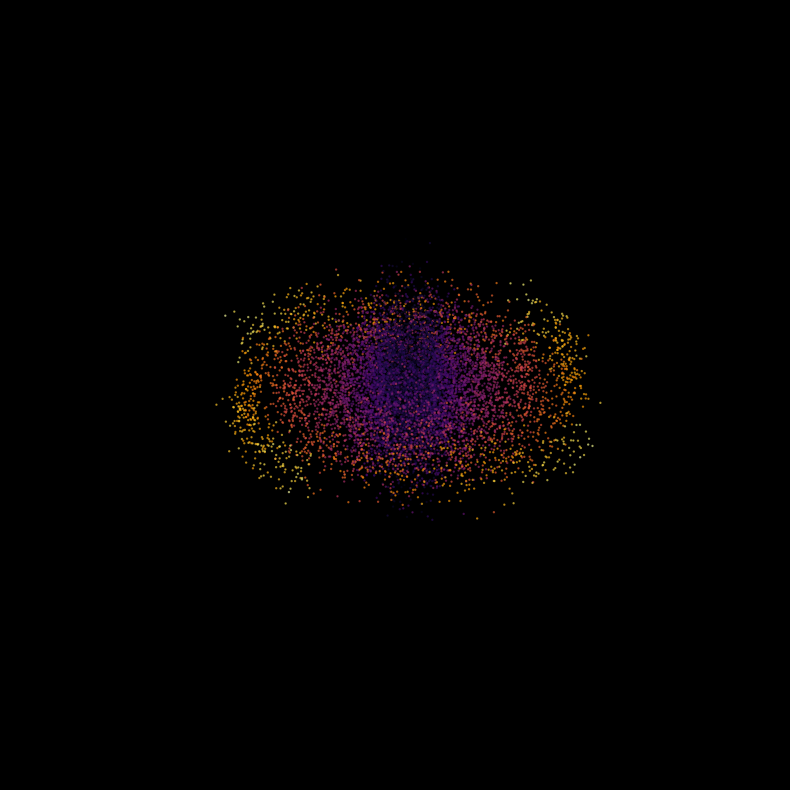

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D

# Çizim kalitesini artırmak için
# plt.style.backend # Bu satır AttributeError'a neden oluyor ve kaldırıldı.
# Yıldız sayısını ve parametreleri belirleyelim
num_stars = 10000

# Rastgele açı ve yarıçap değerleri (logaritmik spiral için)
np.random.seed(42)
theta = np.random.uniform(0, 4 * np.pi, num_stars)
r = np.exp(0.2 * theta) + np.random.normal(0, 0.5, num_stars)

# X, Y, Z koordinatlarının hesaplanması (Spiral kollar ve disk yapısı)
# Kol sayısını artırmak için açılara offset ekleyebiliriz
arm_offset = np.random.choice([0, np.pi/2, np.pi, 3*np.pi/2], num_stars)
x = r * np.cos(theta + arm_offset) + np.random.normal(0, 0.3, num_stars)
y = r * np.sin(theta + arm_offset) + np.random.normal(0, 0.3, num_stars)

# Z ekseni (galaksinin kalınlığı - merkezde şişkin, kenarlarda ince)
z = np.random.normal(0, 0.2, num_stars) / (1 + 0.2 * r)

# 3B Grafik Oluşturma
fig = plt.figure(figsize=(10, 10))
ax = fig.add_subplot(111, projection='3d')

# Arka planı uzay siyahı yapalım
ax.set_facecolor('black')
fig.patch.set_facecolor('black')

# Yıldızları renklendirme (merkez sarı/beyaz, kollar maviye dönük)
colors = plt.cm.inferno(r / np.max(r))

# Noktaları çizdirme
ax.scatter(x, y, z, c=colors, s=0.5, alpha=0.6)

# Eksenleri ve çerçeveyi gizleme (uzay efekti için)
ax.axis('off')

# Görseli göster
plt.show()

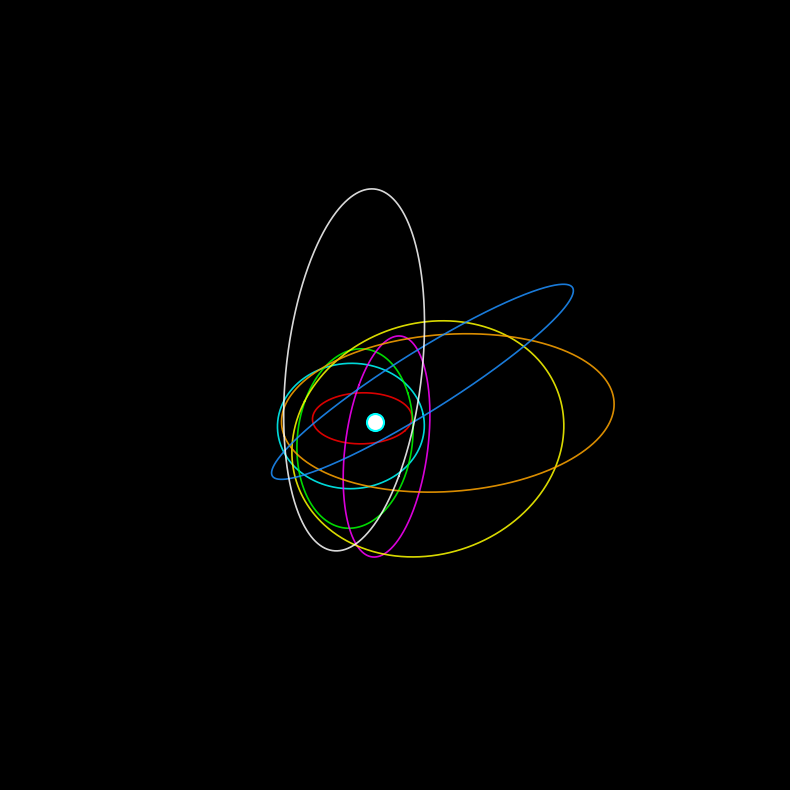

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D

# 3B Grafik Alanı Oluşturma
fig = plt.figure(figsize=(10, 10))
ax = fig.add_subplot(111, projection='3d')

# Arka planı uzay siyahı yapalım
ax.set_facecolor('black')
fig.patch.set_facecolor('black')

# Yörünge parametreleri
num_orbits = 8
theta = np.linspace(0, 2 * np.pi, 1000)
colors = ['red', 'cyan', 'lime', 'magenta', 'yellow', 'orange', 'dodgerblue', 'white']

for i in range(num_orbits):
    # Elips yörünge yarıçapları ve eksantriklik
    a = 1.5 + i * 0.7  # Yarı büyük eksen
    e = 0.3 + (i * 0.03) % 0.4  # Eksantriklik
    b = a * np.sqrt(1 - e**2)  # Yarı küçük eksen

    # Yörüngelerin uzaydaki 3B eğim açıları (inklinasyon)
    inc_x = i * np.pi / 5
    inc_z = i * np.pi / 4

    # 2B Düzlemde Elips Koordinatları
    x_base = a * np.cos(theta) - (a * e)
    y_base = b * np.sin(theta)
    z_base = np.zeros_like(theta)

    # X ve Z eksenlerinde döndürerek 3B yörünge eğimi verme
    # X ekseni rotasyonu
    y1 = y_base * np.cos(inc_x) - z_base * np.sin(inc_x)
    z1 = y_base * np.sin(inc_x) + z_base * np.cos(inc_x)
    x1 = x_base

    # Z ekseni rotasyonu
    x = x1 * np.cos(inc_z) - y1 * np.sin(inc_z)
    y = x1 * np.sin(inc_z) + y1 * np.cos(inc_z)
    z = z1

    # Yörünge çizgilerini çizdirme
    ax.plot(x, y, z, color=colors[i % len(colors)], linewidth=1.2, alpha=0.85)

# Merkezdeki ana kütle (Örn: Yıldız / Karadelik)
ax.scatter([0], [0], [0], color='white', s=150, edgecolor='cyan', linewidth=1.5)

# Görseli netleştirmek için eksenleri gizleyelim
ax.axis('off')

# Görseli göster
plt.show()


In [ ]:
%%writefile cKX5yBZ3hthG.cpp
#include <iostream>
#include <vector>
#include <cmath>

// 3 Boyutlu Vektor Yapısı
struct Vector3 {
    double x, y, z;
};

// Yörünge Sınıfı
class Orbit {
private:
    double semi_major_axis; // a (Yarı büyük eksen)
    double eccentricity;    // e (Eksantriklik)
    double semi_minor_axis; // b (Yarı küçük eksen)
    double inc_x;           // X ekseni eğim açısı
    double inc_z;           // Z ekseni eğim açısı

public:
    Orbit(double a, double e, double ix, double iz)
        : semi_major_axis(a), eccentricity(e), inc_x(ix), inc_z(iz) {
        semi_minor_axis = semi_major_axis * std::sqrt(1.0 - (eccentricity * eccentricity));
    }

    // Belirli bir açı (theta) için 3B yörünge koordinatını hesaplar
    Vector3 calculatePoint(double theta) const {
        // 2D Düzlemde Elips Koordinatları
        double x_base = semi_major_axis * std::cos(theta) - (semi_major_axis * eccentricity);
        double y_base = semi_minor_axis * std::sin(theta);
        double z_base = 0.0;

        // X ekseni rotasyonu (İnklinasyon)
        double y1 = y_base * std::cos(inc_x) - z_base * std::sin(inc_x);
        double z1 = y_base * std::sin(inc_x) + z_base * std::cos(inc_x);
        double x1 = x_base;

        // Z ekseni rotasyonu
        double x = x1 * std::cos(inc_z) - y1 * std::sin(inc_z);
        double y = x1 * std::sin(inc_z) + y1 * std::cos(inc_z);
        double z = z1;

        return {x, y, z};
    }
};

// Simülasyon Yöneticisi
class GalaxySimulation {
private:
    std::vector<Orbit> orbits;

public:
    void addOrbit(double a, double e, double ix, double iz) {
        orbits.emplace_back(a, e, ix, iz);
    }

    void generateOrbitData() {
        int steps = 100; // Her yörünge için nokta sayısı
        int orbitIndex = 0;

        for (const auto& orbit : orbits) {
            std::cout << "--- Yorunge " << ++orbitIndex << " Baslangici ---\n";
            for (int i = 0; i <= steps; ++i) {
                double theta = (2.0 * M_PI * i) / steps;
                Vector3 pt = orbit.calculatePoint(theta);

                // Koordinatları konsola basar (Bunları OpenGL veya Python'a aktarabilirsiniz)
                std::cout << "X: " << pt.x << ", Y: " << pt.y << ", Z: " << pt.z << "\n";
            }
        }
    }
};

int main() {
    GalaxySimulation sim;

    // Farklı boyut ve eğimlerde yörüngeler ekleyelim
    for (int i = 0; i < 8; ++i) {
        double a = 1.5 + i * 0.7;
        double e = 0.3 + (i * 0.03);
        double inc_x = i * (M_PI / 5.0);
        double inc_z = i * (M_PI / 4.0);

        sim.addOrbit(a, e, inc_x, inc_z);
    }

    // Hesaplamaları çalıştır
    sim.generateOrbitData();
    std::cout << "\nC++ Yorunge hesaplamalari basariyla tamamlandi.\n";

    return 0;
}


Overwriting cKX5yBZ3hthG.cpp


In [ ]:
%%bash
g++ -std=c++11 -o galaxy_simulation cKX5yBZ3hthG.cpp -lm
./galaxy_simulation

--- Yorunge 1 Baslangici ---
X: 1.05, Y: 0, Z: 0
X: 1.04704, Y: 0.0898475, Z: 0
X: 1.03817, Y: 0.17934, Z: 0
X: 1.02343, Y: 0.268126, Z: 0
X: 1.00287, Y: 0.355853, Z: 0
X: 0.976585, Y: 0.442175, Z: 0
X: 0.944665, Y: 0.526753, Z: 0
X: 0.907241, Y: 0.609251, Z: 0
X: 0.86446, Y: 0.689346, Z: 0
X: 0.816492, Y: 0.766719, Z: 0
X: 0.763525, Y: 0.841067, Z: 0
X: 0.70577, Y: 0.912096, Z: 0
X: 0.643453, Y: 0.979524, Z: 0
X: 0.576821, Y: 1.04309, Z: 0
X: 0.506136, Y: 1.10253, Z: 0
X: 0.431678, Y: 1.15763, Z: 0
X: 0.35374, Y: 1.20816, Z: 0
X: 0.272631, Y: 1.25391, Z: 0
X: 0.188669, Y: 1.29472, Z: 0
X: 0.102187, Y: 1.33043, Z: 0
X: 0.0135255, Y: 1.36088, Z: 0
X: -0.0769652, Y: 1.38595, Z: 0
X: -0.168928, Y: 1.40556, Z: 0
X: -0.262, Y: 1.41963, Z: 0
X: -0.355814, Y: 1.42809, Z: 0
X: -0.45, Y: 1.43091, Z: 0
X: -0.544186, Y: 1.42809, Z: 0
X: -0.638, Y: 1.41963, Z: 0
X: -0.731072, Y: 1.40556, Z: 0
X: -0.823035, Y: 1.38595, Z: 0
X: -0.913525, Y: 1.36088, Z: 0
X: -1.00219, Y: 1.33043, Z: 0
X: -1.08867, Y

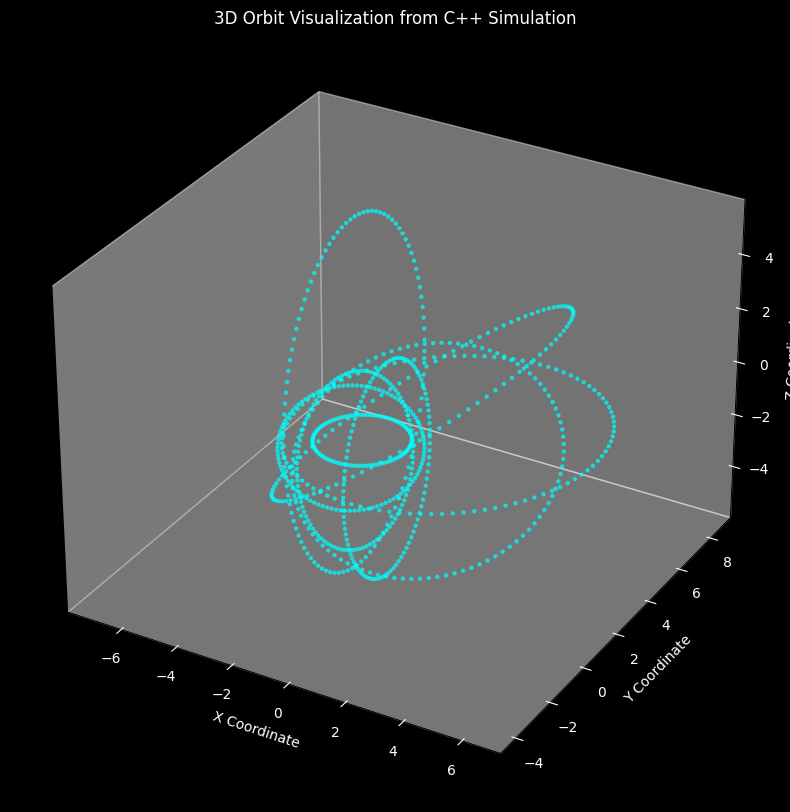

In [ ]:
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D
import re

# Get the standard output from the previous cell where C++ code was executed
cpp_output = get_ipython().getoutput("%%bash\ng++ -std=c++11 -o galaxy_simulation cKX5yBZ3hthG.cpp -lm\n./galaxy_simulation")

# Initialize lists to store coordinates
all_x = []
all_y = []
all_z = []

# Regex to extract X, Y, Z values
coord_pattern = re.compile(r"X: ([-+]?\d*\.?\d+(?:[eE][-+]?\d+)?), Y: ([-+]?\d*\.?\d+(?:[eE][-+]?\d+)?), Z: ([-+]?\d*\.?\d+(?:[eE][-+]?\d+)?)")

# Parse the output
for line in cpp_output:
    match = coord_pattern.match(line)
    if match:
        x_val = float(match.group(1))
        y_val = float(match.group(2))
        z_val = float(match.group(3))
        all_x.append(x_val)
        all_y.append(y_val)
        all_z.append(z_val)

# Create the 3D plot
fig = plt.figure(figsize=(12, 10))
ax = fig.add_subplot(111, projection='3d')

# Set background to black for a space-like appearance
ax.set_facecolor('black')
fig.patch.set_facecolor('black')

# Plot the points
ax.scatter(all_x, all_y, all_z, s=5, alpha=0.6, color='cyan')

# Customize the plot
ax.set_title('3D Orbit Visualization from C++ Simulation', color='white')
ax.set_xlabel('X Coordinate', color='white')
ax.set_ylabel('Y Coordinate', color='white')
ax.set_zlabel('Z Coordinate', color='white')

# Set color of tick labels to white
ax.tick_params(axis='x', colors='white')
ax.tick_params(axis='y', colors='white')
ax.tick_params(axis='z', colors='white')

# Optionally, remove grid lines and axis ticks for a cleaner look
ax.grid(False)

plt.show()

In [ ]:
%%writefile pbArBfhCpBSS.cpp
#include <iostream>
#include <vector>
#include <cmath>
#include <random>

// 3 Boyutlu Yıldız Yapısı (Koordinat ve Renk Değeri)
struct Star {
    double x, y, z;
    double intensity; // Parlaklık veya renk için
};

class GalaxyGenerator {
private:
    int num_stars;
    std::vector<Star> stars;

public:
    GalaxyGenerator(int starCount) : num_stars(starCount) {}

    // Logaritmik spiral galaksi kollarını ve yıldızları hesaplayan fonksiyon
    void generateSpiralGalaxy() {
        stars.clear();
        stars.reserve(num_stars);

        // Rastgele sayı üreticileri
        std::random_device rd;
        std::mt19937 gen(rd());
        std::uniform_real_distribution<double> dist_theta(0.0, 4.0 * M_PI);
        std::normal_distribution<double> dist_noise(0.0, 0.3);
        std::normal_distribution<double> dist_z(0.0, 0.2);

        // Kol ofsetleri (4 ana spiral kol için)
        double arm_offsets[4] = {0.0, M_PI / 2.0, M_PI, 3.0 * M_PI / 2.0};

        for (int i = 0; i < num_stars; ++i) {
            double theta = dist_theta(gen);

            // Logaritmik spiral yarıçap denklemi: r = e^(0.2 * theta)
            double r = std::exp(0.2 * theta) + dist_noise(gen);

            // Rastgele bir kol seçelim
            int arm_idx = i % 4;
            double chosen_offset = arm_offsets[arm_idx];

            // Kartezyen koordinatlara dönüşüm
            double x = r * std::cos(theta + chosen_offset) + dist_noise(gen);
            double y = r * std::sin(theta + chosen_offset) + dist_noise(gen);

            // Z ekseni (galaksi diski kalınlığı - merkezde şişkin)
            double z = dist_z(gen) / (1.0 + 0.2 * r);

            // Yıldızın merkeze olan uzaklığına göre parlaklık/renk yoğunluğu
            double intensity = 1.0 / (1.0 + r * 0.1);

            stars.push_back({x, y, z, intensity});
        }
    }

    // Üretilen verileri dışa aktarma (Örn: OpenGL veya dosya yazmak için)
    const std::vector<Star>& getStars() const {
        return stars;
    }

    // Konsola örnek veriler basma
    void printSampleData(int limit = 10) const {
        std::cout << "--- Spiral Galaksi Yildiz Koordinatlari (Ornek) ---\n";
        for (int i = 0; i < std::min(limit, (int)stars.size()); ++i) {
            std::cout << "Yildiz " << i + 1 << " -> "
                      << "X: " << stars[i].x << ", "
                      << "Y: " << stars[i].y << ", "
                      << "Z: " << stars[i].z << ", "
                      << "Parlaklik: " << stars[i].intensity << "\n";
        }
    }
};

int main() {
    // 10.000 yıldızlı bir galaksi oluşturalım
    GalaxyGenerator galaxy(10000);
    galaxy.generateSpiralGalaxy();

    // Örnek koordinatları ekrana yazdır
    galaxy.printSampleData(5);

    std::cout << "\nC++ ile logaritmik spiral galaksi kollari basariyla modellendi!\n";
    return 0;
}


Overwriting pbArBfhCpBSS.cpp


In [ ]:
%%bash
g++ -std=c++11 -o galaxy_generator pbArBfhCpBSS.cpp -lm
./galaxy_generator

--- Spiral Galaksi Yildiz Koordinatlari (Ornek) ---
Yildiz 1 -> X: -1.38805, Y: -0.787225, Z: -0.420562, Parlaklik: 0.847916
Yildiz 2 -> X: -2.43793, Y: -5.47064, Z: -0.083688, Parlaklik: 0.617361
Yildiz 3 -> X: 1.3447, Y: -0.632374, Z: 0.221923, Parlaklik: 0.853436
Yildiz 4 -> X: -0.850408, Y: 6.63396, Z: 0.117667, Parlaklik: 0.585709
Yildiz 5 -> X: -1.71316, Y: 0.908947, Z: 0.116618, Parlaklik: 0.842249

C++ ile logaritmik spiral galaksi kollari basariyla modellendi!


In [ ]:
%%writefile IWWuWuQsp-mP.cpp
#include <iostream>
#include <vector>
#include <cmath>
#include <random>

// M_PI_2 (pi/2) gibi sabitler cmath'te tanımlı değilse, onları tanımlarız
#ifndef M_PI
#define M_PI 3.14159265358979323846
#endif

#ifndef M_PI_2
#define M_PI_2 (M_PI / 2.0)
#endif

#ifndef M_PI_4
#define M_PI_4 (M_PI / 4.0)
#endif

struct Star {
    double x, y, z;
    double brightness;
};

class GalaxySimulator {
private:
    int total_stars;
    std::vector<Star> stars;

public:
    GalaxySimulator(int starCount) : total_stars(starCount) {}

    void generateGalaxy() {
        stars.clear();
        stars.reserve(total_stars);

        std::random_device rd;
        std::mt19937 gen(rd());

        // Açı aralığını büyülterek kolların sarılmasını sağlıyoruz
        std::uniform_real_distribution<double> dist_theta(0.0, 4.0 * M_PI);
        std::normal_distribution<double> dist_spread(0.0, 0.4);
        std::normal_distribution<double> dist_z(0.0, 0.15);

        // 4 Kollu Spiral İçin Kol Başlangıç Açıları (0, pi/2, pi, 3pi/2)
        double arm_angles[4] = {0.0, M_PI_2, M_PI, 3.0 * M_PI_2};

        for (int i = 0; i < total_stars; ++i) {
            double theta = dist_theta(gen);

            // Logaritmik spiral yarıçapı: r = a * e^(b * theta)
            // b katsayısı (0.3) kolların açılma oranını belirler
            double r = 1.2 * std::exp(0.3 * theta);

            // Hangi kola ait olduğunu seçelim ve rastgelelik (gürültü) ekleyelim
            int arm = i % 4;
            double base_angle = theta + arm_angles[arm] + dist_spread(gen);

            // Kartezyen Koordinatlar
            double x = r * std::cos(base_angle) + dist_spread(gen);
            double y = r * std::sin(base_angle) + dist_spread(gen);

            // Z ekseni (Merkezde şişkin, uçlara doğru ince disk)
            double z = dist_z(gen) * (15.0 / (r + 1.0));

            // Merkeze yakın yıldızlar daha parlak
            double brightness = 1.0 / (1.0 + 0.1 * r);

            stars.push_back({x, y, z, brightness});
        }
    }

    // Tüm yıldızların koordinatlarını ve parlaklığını basan yeni fonksiyon
    void printAllStars() const {
        for (size_t i = 0; i < stars.size(); ++i) {
            std::cout << "Yildiz " << i + 1 << " -> "
                      << "X: " << stars[i].x << ", "
                      << "Y: " << stars[i].y << ", "
                      << "Z: " << stars[i].z << ", "
                      << "Parlaklik: " << stars[i].brightness << "\n";
        }
    }
};

int main() {
    // 20.000 yıldız ile yoğun bir spiral galaksi oluşturalım
    GalaxySimulator galaxy(20000);
    galaxy.generateGalaxy();

    // Tüm yıldız verilerini konsola bas
    galaxy.printAllStars();

    std::cout << "\nC++ Yorunge hesaplamalari basariyla tamamlandi.\n";

    return 0;
}

Overwriting IWWuWuQsp-mP.cpp


In [ ]:
%%bash
g++ -std=c++11 -o galaxy_simulator IWWuWuQsp-mP.cpp -lm
./galaxy_simulator

Yildiz 1 -> X: -3.67064, Y: -1.40434, Z: -0.644944, Parlaklik: 0.722948
Yildiz 2 -> X: 14.6515, Y: -18.8013, Z: 0.071883, Parlaklik: 0.293864
Yildiz 3 -> X: -28.4843, Y: 29.9492, Z: 0.0259857, Parlaklik: 0.192715
Yildiz 4 -> X: 12.9622, Y: 8.11527, Z: 0.12505, Parlaklik: 0.400663
Yildiz 5 -> X: 34.9243, Y: -14.8245, Z: 0.0740535, Parlaklik: 0.210412
Yildiz 6 -> X: 5.84708, Y: -20.1728, Z: 0.281562, Parlaklik: 0.322763
Yildiz 7 -> X: 0.942799, Y: -2.29566, Z: 0.373666, Parlaklik: 0.850305
Yildiz 8 -> X: -23.2462, Y: 18.8784, Z: -0.0483746, Parlaklik: 0.252328
Yildiz 9 -> X: -6.17512, Y: 10.566, Z: 0.0082633, Parlaklik: 0.446392
Yildiz 10 -> X: 27.5997, Y: -2.64073, Z: 0.000466813, Parlaklik: 0.266295
Yildiz 11 -> X: -4.16745, Y: 3.53391, Z: -0.0550394, Parlaklik: 0.637313
Yildiz 12 -> X: -17.7796, Y: -39.3894, Z: 0.0151759, Parlaklik: 0.188642
Yildiz 13 -> X: 4.50893, Y: -5.55528, Z: 0.34483, Parlaklik: 0.582665
Yildiz 14 -> X: 1.52481, Y: -3.19482, Z: 0.0694357, Parlaklik: 0.725195
Yil

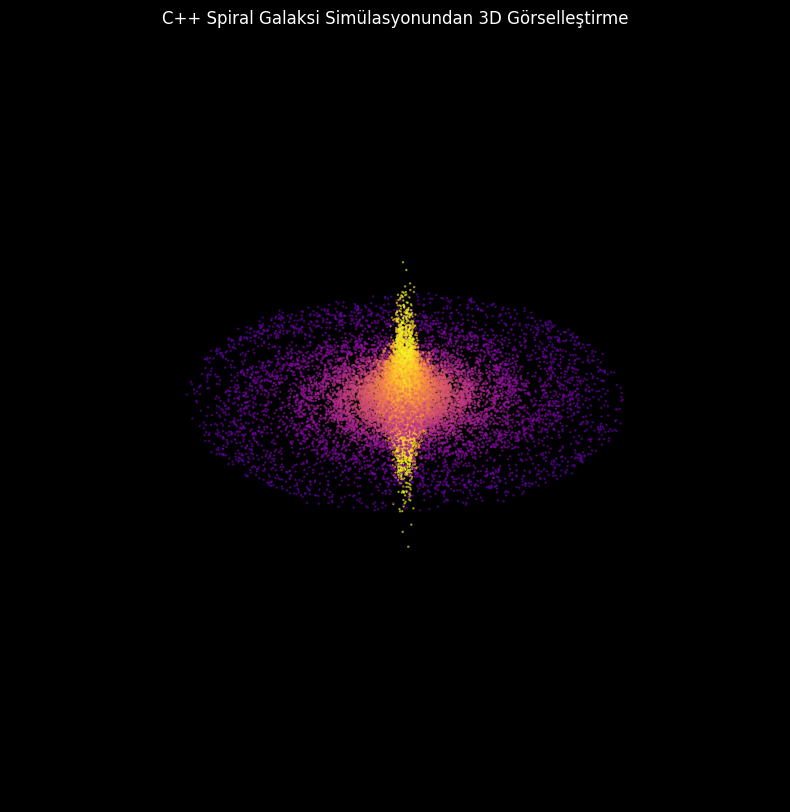

In [ ]:
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D
import re
import numpy as np

# C++ kodunu çalıştır ve çıktıyı al
# Dikkat: Bu, C++ programını tekrar derleyip çalıştıracaktır.
cpp_output = get_ipython().getoutput("%%bash\ng++ -std=c++11 -o galaxy_simulator IWWuWuQsp-mP.cpp -lm\n./galaxy_simulator")

# Koordinatları ve parlaklık değerlerini saklamak için listeler
all_x = []
all_y = []
all_z = []
all_brightness = []

# X, Y, Z ve Parlaklık değerlerini çıkarmak için regex
coord_pattern = re.compile(r"X: ([-+]?\d*\.?\d+(?:[eE][-+]?\d+)?), Y: ([-+]?\d*\.?\d+(?:[eE][-+]?\d+)?), Z: ([-+]?\d*\.?\d+(?:[eE][-+]?\d+)?), Parlaklik: ([-+]?\d*\.?\d+(?:[eE][-+]?\d+)?)")

# Çıktıyı ayrıştır
for line in cpp_output:
    match = coord_pattern.search(line)
    if match:
        x_val = float(match.group(1))
        y_val = float(match.group(2))
        z_val = float(match.group(3))
        brightness_val = float(match.group(4))
        all_x.append(x_val)
        all_y.append(y_val)
        all_z.append(z_val)
        all_brightness.append(brightness_val)

# 3D grafiği oluştur
fig = plt.figure(figsize=(12, 10))
ax = fig.add_subplot(111, projection='3d')

# Uzay benzeri bir görünüm için arka planı siyah yap
ax.set_facecolor('black')
fig.patch.set_facecolor('black')

# Yıldızları parlaklık değerlerine göre renklendir
# Parlaklık değerlerini 0-1 aralığına normalize edip renk haritasına uygulayalım
# Düşük parlaklık değerleri için daha iyi görünüm sağlamak adına normalize işlemi.
if all_brightness:
    normalized_brightness = np.array(all_brightness) / np.max(all_brightness)
    colors = plt.cm.plasma(normalized_brightness)
else:
    colors = 'white' # Eğer hiç yıldız yoksa beyaz renk kullan

# Noktaları çizdir
ax.scatter(all_x, all_y, all_z, c=colors, s=0.5, alpha=0.6)

# Grafiği özelleştir
ax.set_title('C++ Spiral Galaksi Simülasyonundan 3D Görselleştirme', color='white')
ax.set_xlabel('X Koordinatı', color='white')
ax.set_ylabel('Y Koordinatı', color='white')
ax.set_zlabel('Z Koordinatı', color='white')

# Tik etiketlerinin rengini beyaz yap
ax.tick_params(axis='x', colors='white')
ax.tick_params(axis='y', colors='white')
ax.tick_params(axis='z', colors='white')

# Eksenleri ve çerçeveyi gizle (daha temiz bir görünüm için)
ax.axis('off')

plt.show()

In [ ]:
%%bash
g++ -std=c++11 -o galaxy_simulator IWWuWuQsp-mP.cpp -lm
./galaxy_simulator

Toplam 20000 adet yildiz basariyla hesaplandi.
Ornek Ilk 3 Yildiz Koordinati:
 -> X: 3.03629, Y: 10.8878, Z: -0.152431
 -> X: -8.2925, Y: -20.6764, Z: -0.037932
 -> X: -0.0267311, Y: -2.10688, Z: -0.0172047


In [ ]:
%%writefile galaxy_renderer.cpp
#include <iostream>
#include <vector>
#include <cmath>
#include <random>
#include <fstream>
#include <string>

// M_PI cmath'te tanımlı değilse, onu tanımlarız
#ifndef M_PI
#define M_PI 3.14159265358979323846
#endif

struct Particle {
    double x, y, z;
    int type; // 0: Kol yıldızı, 1: Çekirdek (Bulutsu), 2: Arka plan
};

class GalaxyRenderer {
private:
    int num_particles;
    std::vector<Particle> galaxy;

public:
    GalaxyRenderer(int count) : num_particles(count) {}

    void createGalaxy() {
        galaxy.clear();
        galaxy.reserve(num_particles);

        std::random_device rd;
        std::mt19937 gen(rd());
        std::uniform_real_distribution<double> dist_theta(0.0, 4.0 * M_PI);
        std::normal_distribution<double> dist_noise(0.0, 0.35);
        std::normal_distribution<double> dist_bulge(0.0, 0.8);
        std::uniform_real_distribution<double> dist_type(0.0, 1.0);

        // 2 Kollu Spiral Yapı İçin Açı Ofsetleri
        double arm_offsets[2] = {0.0, M_PI};

        for (int i = 0; i < num_particles; ++i) {
            Particle p;

            // %20 oranında merkez çekirdek (bulutsu) oluşturalım
            if (dist_type(gen) < 0.2) { // Yaklaşık %20 çekirdek partikülü
                p.x = dist_bulge(gen);
                p.y = dist_bulge(gen);
                p.z = dist_bulge(gen) * 0.5;
                p.type = 1; // Çekirdek
            }
            else { // Spiral kol partikülleri
                double theta = dist_theta(gen);
                // r = a * e^(b * theta) formülü ile logaritmik spiral
                double r = 0.8 * std::exp(0.35 * theta);

                int arm = i % 2; // Basitçe 2 kola dağıt
                double angle = theta + arm_offsets[arm] + dist_noise(gen);

                p.x = r * std::cos(angle) + dist_noise(gen);
                p.y = r * std::sin(angle) + dist_noise(gen);
                // Z ekseni galaksi merkezinde daha kalın, dışa doğru incelir
                p.z = dist_noise(gen) * (2.0 / (r + 1.0));
                p.type = 0; // Kol yıldızı
            }

            galaxy.push_back(p);
        }
    }

    // Verileri Python ile çizdirmek veya kaydetmek için CSV formatına aktarma
    void exportToCSV(const std::string& filename) const {
        std::ofstream file(filename);
        if (!file.is_open()) {
            std::cerr << "Error: Could not open file " << filename << std::endl;
            return;
        }

        // CSV başlığını yaz
        file << "x,y,z,type\n";

        // Tüm parçacık verilerini yaz
        for (const auto& p : galaxy) {
            file << p.x << "," << p.y << "," << p.z << "," << p.type << "\n";
        }

        file.close();
        std::cout << "Galaxy data exported to " << filename << std::endl;
    }
};

int main() {
    // 25.000 parçacıklı bir galaksi oluşturalım
    GalaxyRenderer renderer(25000);
    renderer.createGalaxy();

    // Verileri CSV dosyasına aktar
    renderer.exportToCSV("galaxy_data.csv");

    return 0;
}


Overwriting galaxy_renderer.cpp


In [ ]:
%%bash
g++ -std=c++11 -o galaxy_renderer galaxy_renderer.cpp -lm
./galaxy_renderer

Galaxy data exported to galaxy_data.csv


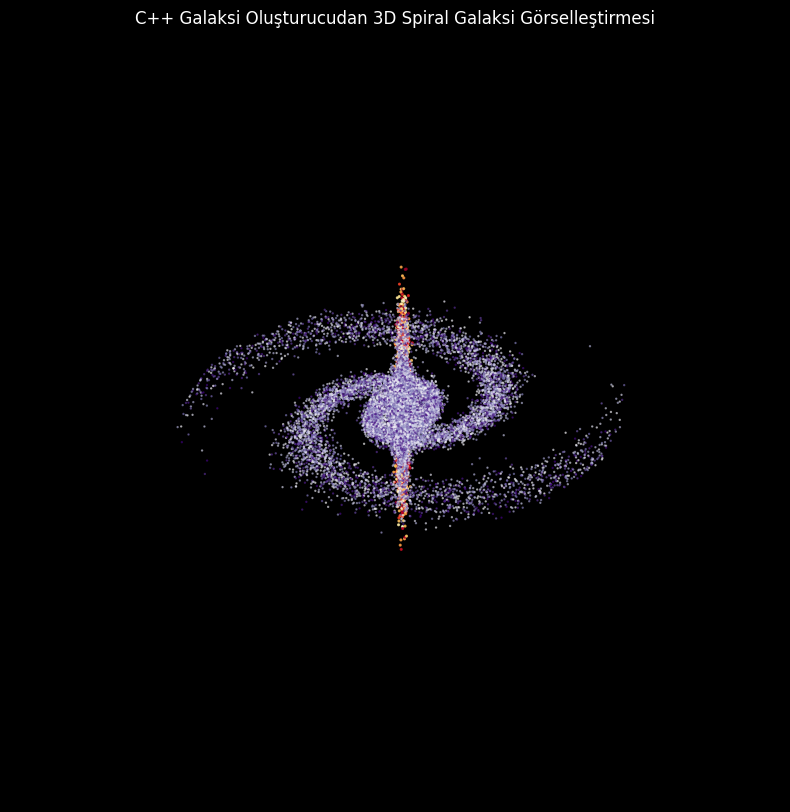

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D
import numpy as np

# CSV dosyasını oku
try:
    df = pd.read_csv('galaxy_data.csv')
except FileNotFoundError:
    print("Error: 'galaxy_data.csv' not found. Please ensure the C++ code was compiled and run successfully.")
    exit()

# 3D grafiği oluştur
fig = plt.figure(figsize=(12, 10))
ax = fig.add_subplot(111, projection='3d')

# Arka planı siyah yap (uzay görünümü için)
ax.set_facecolor('black')
fig.patch.set_facecolor('black')

# Parçacık tiplerine göre renk ataması
# type 0: Kol yıldızları (mor/mavi tonları)
# type 1: Çekirdek (sarı/turuncu tonları)
# Diğer tipler için varsayılan renk (kullanılmıyor ama iyi pratik)

# Colormap'ler ve normalize ediciler
cmap_arms = plt.cm.Purples
cmap_bulge = plt.cm.YlOrRd

# Kol yıldızları (type = 0)
arm_stars = df[df['type'] == 0]
ax.scatter(arm_stars['x'], arm_stars['y'], arm_stars['z'],
           c=cmap_arms(np.random.rand(len(arm_stars))),
           s=0.5, alpha=0.6, label='Spiral Kol Yıldızları')

# Çekirdek parçacıkları (type = 1)
bulge_particles = df[df['type'] == 1]
ax.scatter(bulge_particles['x'], bulge_particles['y'], bulge_particles['z'],
           c=cmap_bulge(np.random.rand(len(bulge_particles))),
           s=1.5, alpha=0.8, label='Çekirdek Parçacıkları')

# Grafiği özelleştir
ax.set_title('C++ Galaksi Oluşturucudan 3D Spiral Galaksi Görselleştirmesi', color='white')
ax.set_xlabel('X Koordinatı', color='white')
ax.set_ylabel('Y Koordinatı', color='white')
ax.set_zlabel('Z Koordinatı', color='white')

# Tik etiketlerinin rengini beyaz yap
ax.tick_params(axis='x', colors='white')
ax.tick_params(axis='y', colors='white')
ax.tick_params(axis='z', colors='white')

# Eksenleri ve çerçeveyi gizle
ax.axis('off')

# Gösterge ekle (opsiyonel)
# ax.legend(loc='upper left', frameon=False, labelcolor='white')

plt.show()